# California Housing Price Prediction
### DATHEON – Machine Learning & Data Science Internship

## 1. Introduction

This project focuses on predicting California housing prices using machine learning regression algorithms.

The California Housing dataset is used to train and compare three regression models: Linear Regression, Ridge Regression, and Lasso Regression.

## 2. Objectives

- Explore the California Housing dataset.
- Handle missing values.
- Perform exploratory data analysis.
- Apply feature engineering and scaling.
- Implement OLS, Ridge, and Lasso regression.
- Optimize models using GridSearchCV.
- Evaluate models using RMSE, MAE, and R².
- Visualize predictions and residuals.

## 3. Importing Required Libraries

The required Python libraries are imported for data manipulation, visualization, preprocessing, model training, and evaluation.

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, Ridge, Lasso

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

import warnings
warnings.filterwarnings('ignore')

sns.set_style("whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


## 4. Dataset Loading

The California Housing dataset is loaded using Pandas. The first five records and dataset dimensions are displayed to understand its structure.

In [ ]:
df = pd.read_csv("housing.csv")

display(df.head())

print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


Dataset Shape: (20640, 10)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


## 5. Dataset Overview

The dataset is examined using descriptive statistics, data types, missing values, and duplicate records.

In [ ]:
display(df.describe())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000



Data Types:
longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
ocean_proximity        object
dtype: object

Missing Values:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Duplicate Records: 0


## 6. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand feature distributions and identify patterns in the housing dataset.

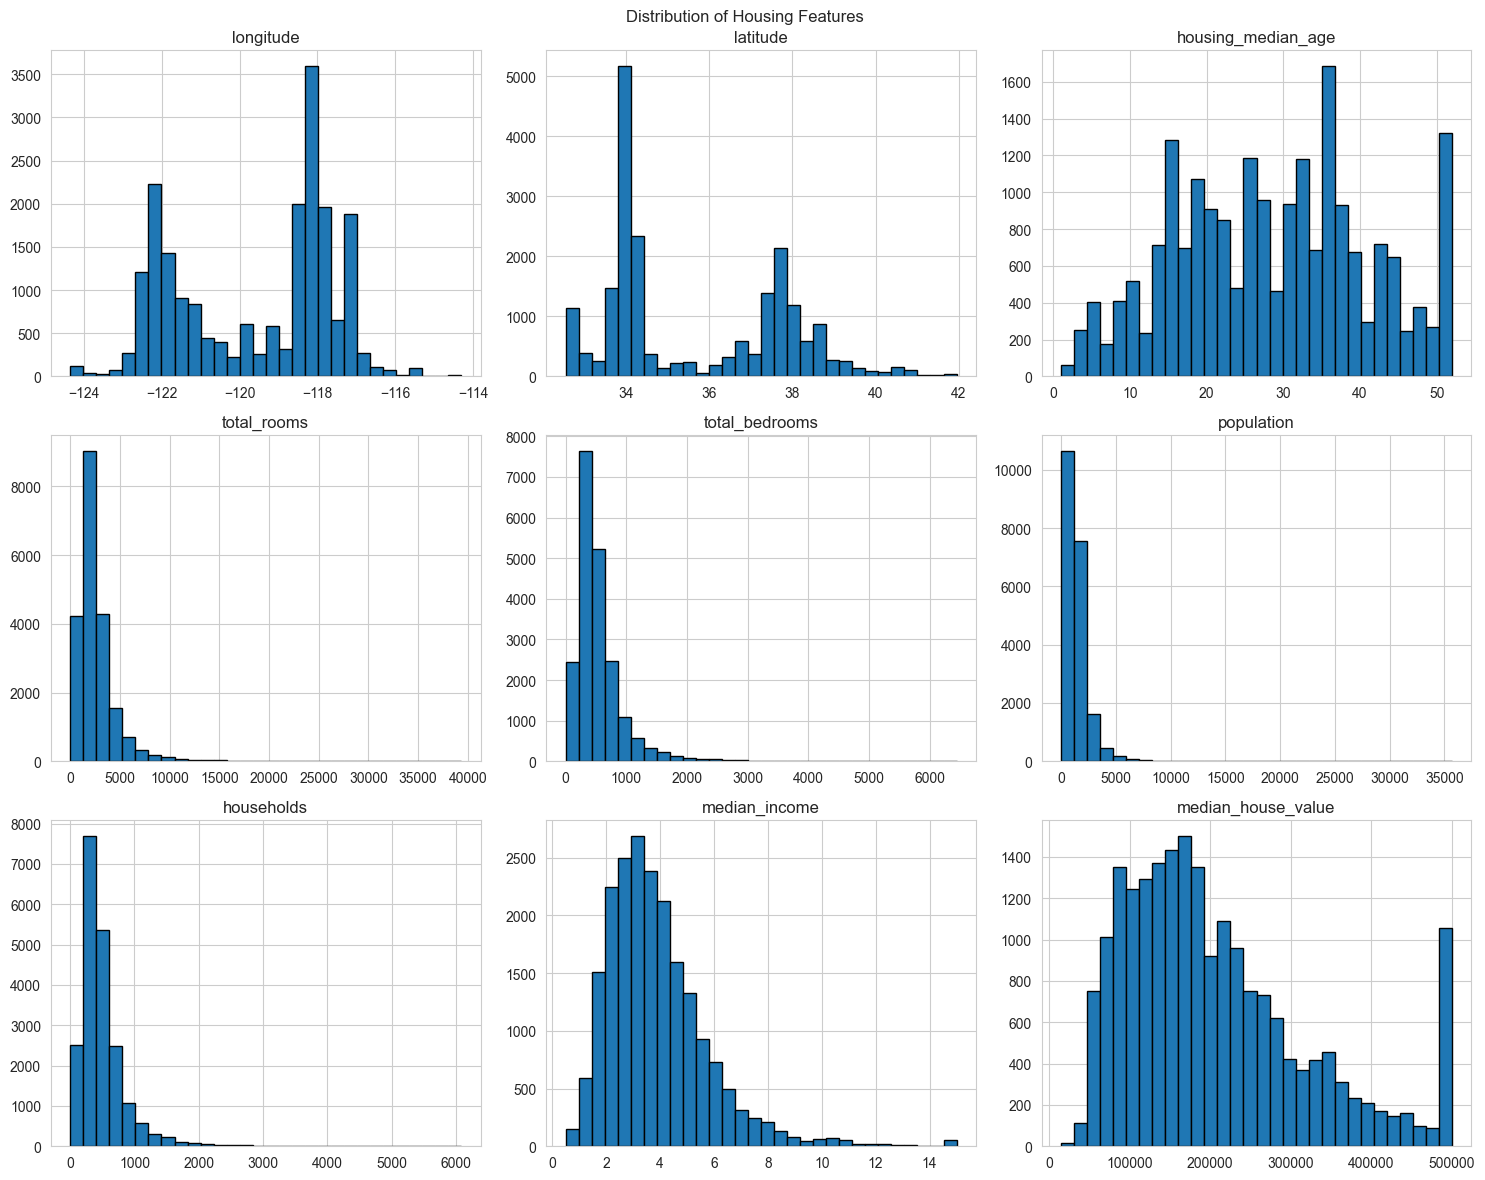

In [ ]:
df.hist(
    figsize=(15, 12),
    bins=30,
    edgecolor='black'
)

plt.suptitle("Distribution of Housing Features")
plt.tight_layout()
plt.show()

## 7. Correlation Analysis

A correlation matrix and heatmap are generated to identify relationships between numerical features and the target variable.

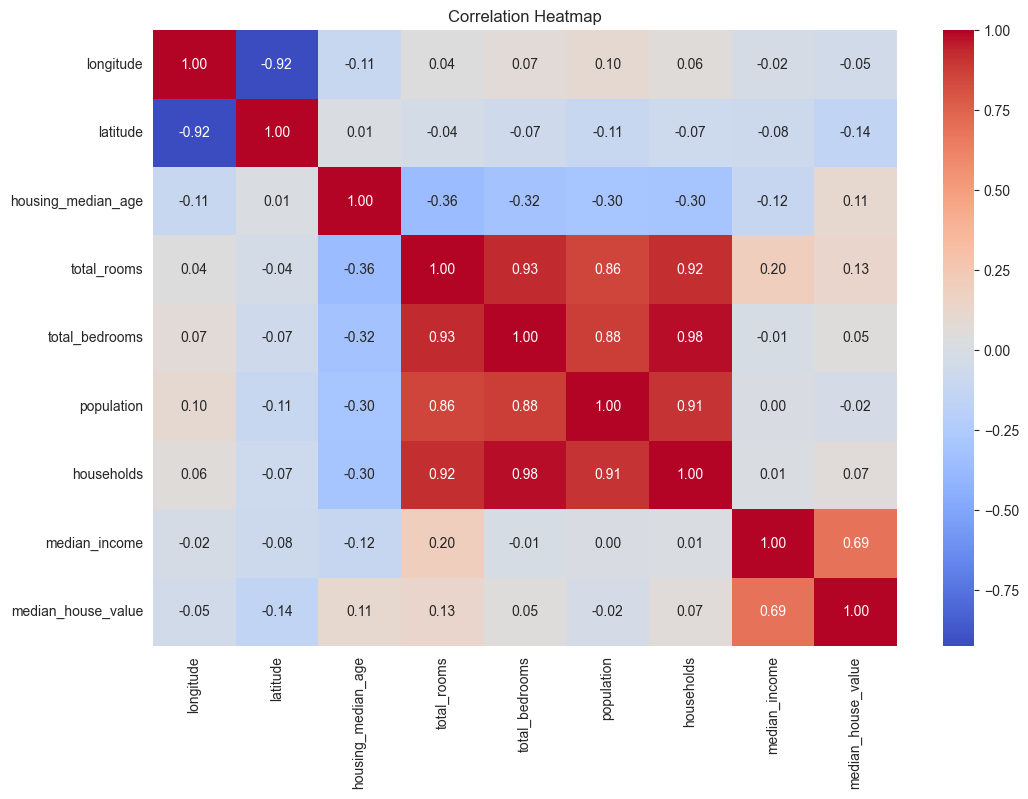

In [ ]:
numeric_df = df.select_dtypes(include=np.number)
correlation = numeric_df.corr()
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")
plt.show()

## 8. Missing Value Handling

Missing values are identified and handled using median imputation to prepare the dataset for model training.

In [ ]:
print("Missing Values Before Imputation:")
print(df.isnull().sum())
df['total_bedrooms'] = df['total_bedrooms'].fillna(
    df['total_bedrooms'].median()
)
print("\nMissing Values After Imputation:")
print(df.isnull().sum())

Missing Values Before Imputation:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Missing Values After Imputation:
longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64


## 9. Feature Engineering

New features are created from existing attributes to improve the predictive performance of regression models.

In [ ]:
df['rooms_per_household'] = (
    df['total_rooms'] / df['households']
)

df['bedrooms_per_room'] = (
    df['total_bedrooms'] / df['total_rooms']
)

df['population_per_household'] = (
    df['population'] / df['households']
)
display(df[['rooms_per_household',
            'bedrooms_per_room',
            'population_per_household']].head())

print("Feature Engineering Completed!")

,rooms_per_household,bedrooms_per_room,population_per_household
0,6.984127,0.146591,2.555556
1,6.238137,0.155797,2.109842
2,8.288136,0.129516,2.802260
3,5.817352,0.184458,2.547945
4,6.281853,0.172096,2.181467


Feature Engineering Completed!


## 10. Feature and Target Selection

The input features and target variable are separated. The median house value is selected as the target variable for prediction.

In [ ]:
X = df.drop('median_house_value', axis=1)

y = df['median_house_value']

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

Input Features Shape: (20640, 12)
Target Shape: (20640,)


## 11. Train-Test Split

The dataset is divided into training and testing sets using an 80/20 split. The training data is used to build the models, while the testing data is used for evaluation.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

Training Samples: 16512
Testing Samples: 4128


## 12. Data Preprocessing

Numerical features are standardized using StandardScaler, and categorical features are encoded using OneHotEncoder. ColumnTransformer is used to apply the transformations.

In [ ]:
numerical_features = X_train.select_dtypes(
    include=np.number
).columns

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns

numerical_transformer = Pipeline([
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numerical_transformer, numerical_features),
    ('cat', categorical_transformer, categorical_features)
])

print("Data Preprocessing Completed!")

Data Preprocessing Completed!


## 13. Ordinary Least Squares (OLS) Regression

Linear Regression is implemented as the baseline model. It predicts house prices by minimizing the sum of squared errors between actual and predicted values.

In [ ]:
ols_model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])
ols_model.fit(X_train, y_train)
ols_predictions = ols_model.predict(X_test)

print("OLS Regression trained successfully!")

OLS Regression trained successfully!


## 14. Ridge Regression (L2 Regularization)

Ridge Regression uses L2 regularization to reduce large coefficient values, handle multicollinearity, and control overfitting.

In [ ]:
ridge_model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', Ridge(alpha=1.0))
])
ridge_model.fit(X_train, y_train)
ridge_predictions = ridge_model.predict(X_test)

print("Ridge Regression trained successfully!")

Ridge Regression trained successfully!


## 15. Lasso Regression (L1 Regularization)

Lasso Regression uses L1 regularization to reduce model complexity and perform feature selection by shrinking less important coefficients towards zero.

In [ ]:
lasso_model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', Lasso(alpha=0.1, max_iter=10000))
])
lasso_model.fit(X_train, y_train)
lasso_predictions = lasso_model.predict(X_test)

print("Lasso Regression trained successfully!")

Lasso Regression trained successfully!


## 16. Hyperparameter Tuning

GridSearchCV is used to identify the optimal alpha values for Ridge and Lasso regression models using cross-validation.

In [ ]:
ridge_params = {
    'regressor__alpha': [0.01, 0.1, 1, 10, 100]
}

ridge_grid = GridSearchCV(
    ridge_model,
    ridge_params,
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

ridge_grid.fit(X_train, y_train)

best_ridge = ridge_grid.best_estimator_

print("Best Ridge Parameters:", ridge_grid.best_params_)

Best Ridge Parameters: {'regressor__alpha': 1}


## 17. Lasso Hyperparameter Tuning

GridSearchCV is applied to Lasso Regression to find the best alpha value and improve model performance.

In [ ]:
lasso_params = {
    'regressor__alpha': [0.001, 0.01, 0.1, 1, 10]
}

lasso_grid = GridSearchCV(
    lasso_model,
    lasso_params,
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

lasso_grid.fit(X_train, y_train)

best_lasso = lasso_grid.best_estimator_

print("Best Lasso Parameters:", lasso_grid.best_params_)

Best Lasso Parameters: {'regressor__alpha': 1}


## 18. Model Performance Evaluation

OLS, Ridge, and Lasso models are evaluated using RMSE, MAE, and R² scores. A comparison table is generated to identify the best-performing model.

In [ ]:
predictions = {
    'OLS': ols_model.predict(X_test),
    'Ridge': best_ridge.predict(X_test),
    'Lasso': best_lasso.predict(X_test)
}

results = []

for name, pred in predictions.items():

    rmse = np.sqrt(mean_squared_error(y_test, pred))
    mae = mean_absolute_error(y_test, pred)
    r2 = r2_score(y_test, pred)

    results.append({
        'Model': name,
        'RMSE': rmse,
        'MAE': mae,
        'R2 Score': r2
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,RMSE,MAE,R2 Score
0,OLS,72668.5384,50888.6600,0.5970
1,Ridge,72677.9215,50897.5787,0.5969
2,Lasso,72668.9686,50889.7349,0.5970


## 19. Model Performance Visualization

A bar chart is generated to compare the RMSE values of OLS, Ridge, and Lasso regression models.

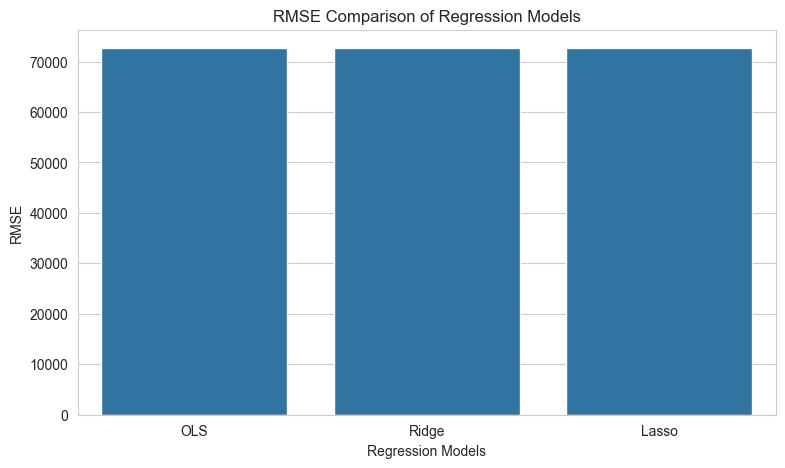

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x='Model',
    y='RMSE'
)

plt.title("RMSE Comparison of Regression Models")
plt.xlabel("Regression Models")
plt.ylabel("RMSE")

plt.show()

## 20. Actual vs Predicted Visualization

Actual and predicted house values are compared using scatter plots. The reference line represents perfect predictions.

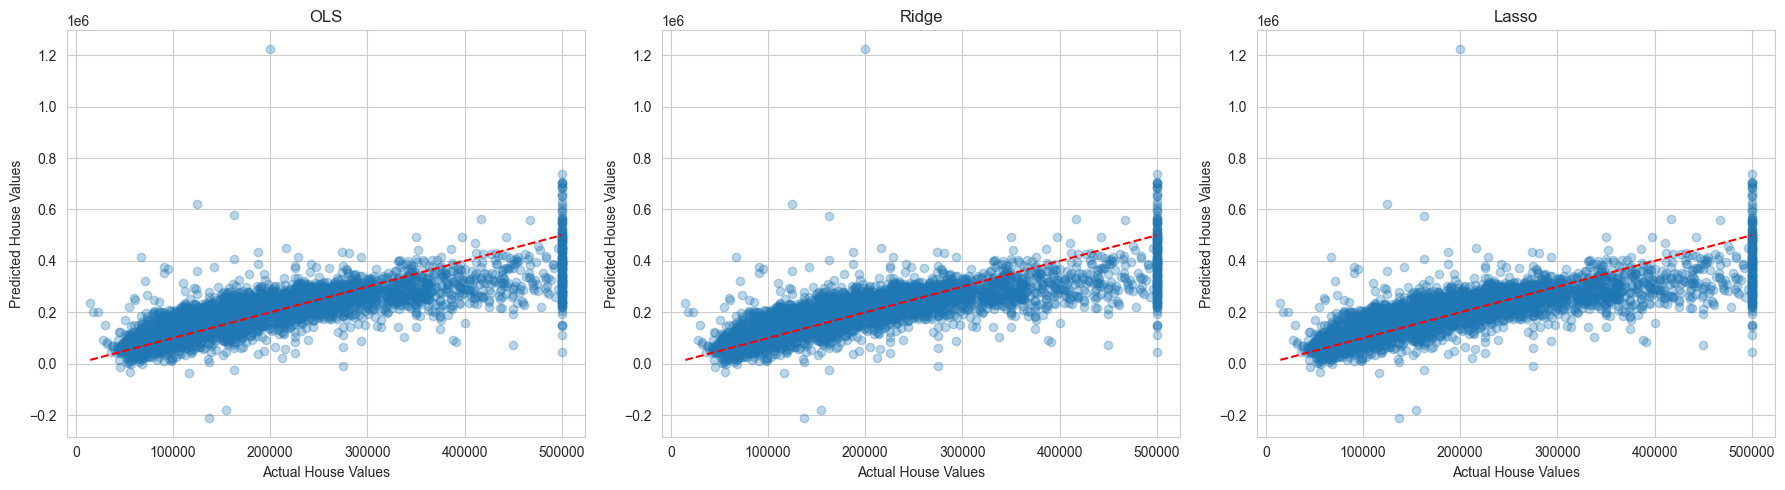

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, pred) in zip(axes, predictions.items()):

    ax.scatter(y_test, pred, alpha=0.3)

    ax.plot(
        [y_test.min(), y_test.max()],
        [y_test.min(), y_test.max()],
        'r--'
    )

    ax.set_title(name)
    ax.set_xlabel("Actual House Values")
    ax.set_ylabel("Predicted House Values")

plt.tight_layout()
plt.show()

## 21. Residual Error Analysis

Residuals represent the differences between actual and predicted house values. Residual distribution plots are generated to analyze prediction errors.

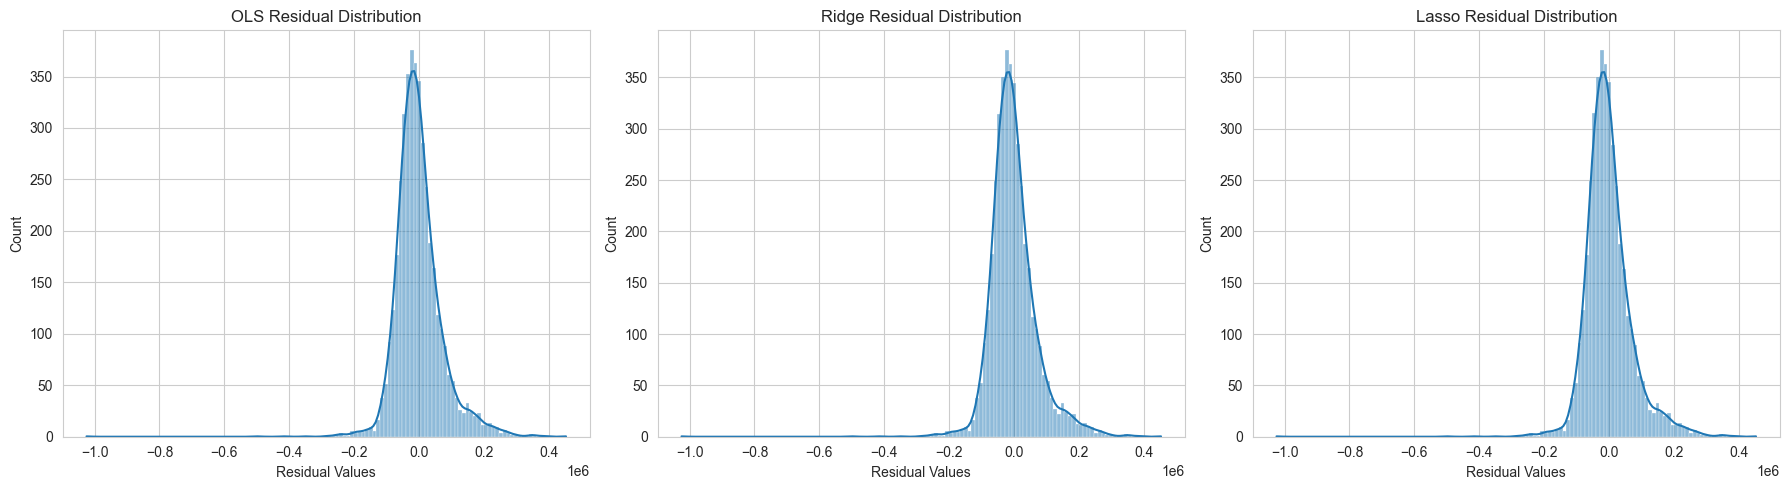

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, pred) in zip(axes, predictions.items()):

    residuals = y_test - pred

    sns.histplot(
        residuals,
        kde=True,
        ax=ax
    )

    ax.set_title(name + " Residual Distribution")
    ax.set_xlabel("Residual Values")

plt.tight_layout()
plt.show()

## 22. Conclusion

The California Housing Price Prediction project was successfully implemented using OLS, Ridge, and Lasso regression algorithms.

Data preprocessing, feature engineering, and hyperparameter tuning were performed.

The models were evaluated using RMSE, MAE, and R² scores. Model comparison, actual versus predicted plots, and residual distributions were generated.

OLS achieved the lowest RMSE and MAE among the three models.

This project provided practical experience in regression modeling, regularization, feature engineering, and model evaluation using Python and Scikit-learn.

## 23. Final Model Comparison

The final performance of all three regression models is displayed to identify the best-performing model.

In [ ]:
print("DATHEON INTERNSHIP - TASK 2")
print("FINAL MODEL PERFORMANCE")
print("-" * 50)

display(results_df.round(4))

best_model = results_df.loc[
    results_df['RMSE'].idxmin(), 'Model'
]

print("\nBest Performing Model:", best_model)
print("Dataset Used: California Housing Dataset")
print("Total Samples:", len(df))
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

DATHEON INTERNSHIP - TASK 2
FINAL MODEL PERFORMANCE
--------------------------------------------------


,Model,RMSE,MAE,R2 Score
0,OLS,72668.5384,50888.6600,0.5970
1,Ridge,72677.9215,50897.5787,0.5969
2,Lasso,72668.9686,50889.7349,0.5970



Best Performing Model: OLS
Dataset Used: California Housing Dataset
Total Samples: 20640
Training Samples: 16512
Testing Samples: 4128


## 24. Interaction Feature Engineering

An interaction feature is created by combining median income and housing median age to capture their combined relationship with house prices.

In [ ]:
df['income_age_interaction'] = (
    df['median_income'] * df['housing_median_age']
)
display(df[['median_income',
            'housing_median_age',
            'income_age_interaction']].head())

print("Interaction Feature Created Successfully!")

,median_income,housing_median_age,income_age_interaction
0,8.3252,41.0,341.3332
1,8.3014,21.0,174.3294
2,7.2574,52.0,377.3848
3,5.6431,52.0,293.4412
4,3.8462,52.0,200.0024


Interaction Feature Created Successfully!


## 25. Multicollinearity Analysis

Variance Inflation Factor (VIF) is used to identify multicollinearity among numerical features.

Ridge and Lasso regularization techniques are used to reduce the impact of highly correlated features.

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
X_vif = df.select_dtypes(include=np.number).drop(
    columns=['median_house_value']
)
X_vif = X_vif.fillna(X_vif.median())
vif_data = pd.DataFrame()

vif_data['Feature'] = X_vif.columns

vif_data['VIF'] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]
display(vif_data.sort_values(
    by='VIF',
    ascending=False
).round(2))

,Feature,VIF
4,total_bedrooms,36.25
6,households,34.74
3,total_rooms,17.10
1,latitude,9.36
11,income_age_interaction,9.13
0,longitude,9.08
7,median_income,7.51
5,population,6.69
2,housing_median_age,5.41
9,bedrooms_per_room,2.19


In [25]:
%pip install statsmodels

   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB 217.9 kB/s eta 0:00:53
   ---------------------------------------- 0.0/11.4 MB 217.9 kB/s eta 0:00:52
   ---------------------------------------- 0.1/11.4 MB 302.7 kB/s eta 0:00:38
   ---------------------------------------- 0.1/11.4 MB 302.7 kB/s eta 0:00:38
   ---------------------------------------- 0.1/11.4 MB 379.3 kB/s eta 0:00:30
    --------------------------------------- 0.1/11.4 MB 448.2 kB/s eta 0:00:26
    --------------------------------------- 0.1/11.4 MB 448.2 kB/s eta 0:00:26
    --------------------------------------- 0.1/11.4 MB 448.2 kB/s eta 0:00:26
    --------------------------------------- 0.1/11.4 MB 448.2 kB/s eta 0:00:26
    -----


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: C:\Users\gavya\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


## 26. Handling Multicollinearity

Highly correlated features are identified using VIF analysis. The redundant features total_bedrooms, households, and total_rooms are removed to reduce multicollinearity.

In [ ]:
df = df.drop(columns=['total_bedrooms', 'households', 'total_rooms'])

print("Highly correlated features removed successfully!")
print("\nUpdated Dataset Shape:", df.shape)

Highly correlated features removed successfully!

Updated Dataset Shape: (20640, 11)


## 27. Updated VIF Analysis

VIF is recalculated after removing highly correlated features to examine the remaining multicollinearity.

In [ ]:
X_vif = df.select_dtypes(include=np.number).drop(
    columns=['median_house_value']
)

vif_data = pd.DataFrame()

vif_data['Feature'] = X_vif.columns

vif_data['VIF'] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

display(vif_data.sort_values(
    by='VIF',
    ascending=False
).round(2))

,Feature,VIF
1,latitude,9.13
0,longitude,8.85
8,income_age_interaction,8.75
4,median_income,6.73
2,housing_median_age,5.22
6,bedrooms_per_room,1.58
5,rooms_per_household,1.30
3,population,1.14
7,population_per_household,1.01


## 28. Updated Feature and Target Selection

The updated dataset is used to separate input features and the target variable before model training.

In [ ]:
X = df.drop('median_house_value', axis=1)

y = df['median_house_value']
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Updated Input Features:", X.shape)
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

Updated Input Features: (20640, 10)
Training Samples: 16512
Testing Samples: 4128


## 29. Updated Data Preprocessing

The updated numerical and categorical features are preprocessed using StandardScaler and OneHotEncoder to prepare the dataset for regression modeling.

In [ ]:
numerical_features = X_train.select_dtypes(
    include=np.number
).columns

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns
numerical_transformer = Pipeline([
    ('scaler', StandardScaler())
])
categorical_transformer = Pipeline([
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numerical_transformer, numerical_features),
    ('cat', categorical_transformer, categorical_features)
])

print("Updated Preprocessing Completed!")

Updated Preprocessing Completed!


## 30. Updated Regression Models

OLS, Ridge, and Lasso regression models are retrained using the updated dataset and preprocessing pipeline.

In [ ]:
ols_model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

ols_model.fit(X_train, y_train)
ols_predictions = ols_model.predict(X_test)
ridge_model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', Ridge())
])

ridge_model.fit(X_train, y_train)
ridge_predictions = ridge_model.predict(X_test)
lasso_model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', Lasso(max_iter=10000))
])

lasso_model.fit(X_train, y_train)
lasso_predictions = lasso_model.predict(X_test)

print("All three regression models retrained successfully!")

All three regression models retrained successfully!


## 31. Ridge Hyperparameter Tuning

GridSearchCV is used to identify the optimal alpha value for Ridge Regression using 5-fold cross-validation.

In [ ]:
ridge_params = {
    'regressor__alpha': [0.01, 0.1, 1, 10, 100]
}

ridge_grid = GridSearchCV(
    ridge_model,
    ridge_params,
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

ridge_grid.fit(X_train, y_train)

best_ridge = ridge_grid.best_estimator_

print("Best Ridge Parameters:", ridge_grid.best_params_)

Best Ridge Parameters: {'regressor__alpha': 1}


## 32. Lasso Hyperparameter Tuning

GridSearchCV is used to identify the optimal alpha value for Lasso Regression using 5-fold cross-validation.

In [ ]:
lasso_params = {
    'regressor__alpha': [0.001, 0.01, 0.1, 1, 10]
}

lasso_grid = GridSearchCV(
    lasso_model,
    lasso_params,
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

lasso_grid.fit(X_train, y_train)

best_lasso = lasso_grid.best_estimator_

print("Best Lasso Parameters:", lasso_grid.best_params_)

Best Lasso Parameters: {'regressor__alpha': 1}


## 33. Final Model Performance Evaluation

The optimized OLS, Ridge, and Lasso regression models are evaluated using RMSE, MAE, and R² scores to compare their predictive performance.

In [ ]:
predictions = {
    'OLS': ols_model.predict(X_test),
    'Ridge': best_ridge.predict(X_test),
    'Lasso': best_lasso.predict(X_test)
}

results = []

for name, pred in predictions.items():

    rmse = np.sqrt(mean_squared_error(y_test, pred))
    mae = mean_absolute_error(y_test, pred)
    r2 = r2_score(y_test, pred)

    results.append({
        'Model': name,
        'RMSE': rmse,
        'MAE': mae,
        'R2 Score': r2
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,RMSE,MAE,R2 Score
0,OLS,76414.2677,52720.7071,0.5544
1,Ridge,76422.3339,52727.4811,0.5543
2,Lasso,76414.6372,52721.6498,0.5544


## 34. Updated Model Comparison

The RMSE values of the optimized regression models are compared using a bar chart.

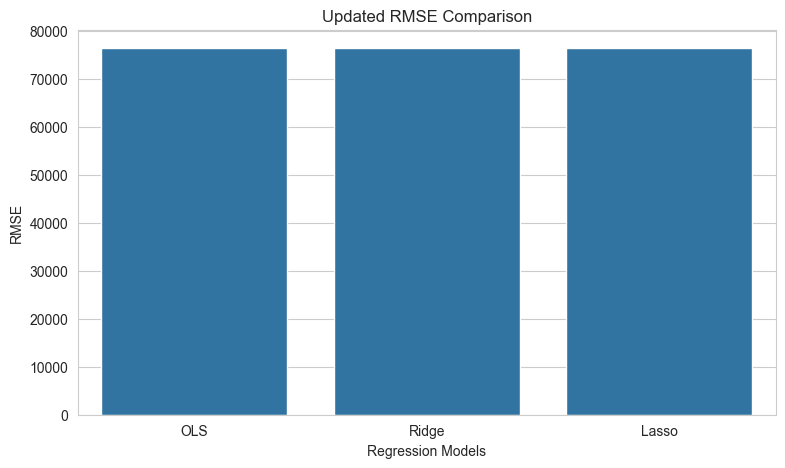

In [36]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x='Model',
    y='RMSE'
)

plt.title("Updated RMSE Comparison")
plt.xlabel("Regression Models")
plt.ylabel("RMSE")

plt.show()

## 35. Actual vs Predicted Visualization

Actual and predicted house values are compared to examine the performance of the updated regression models.

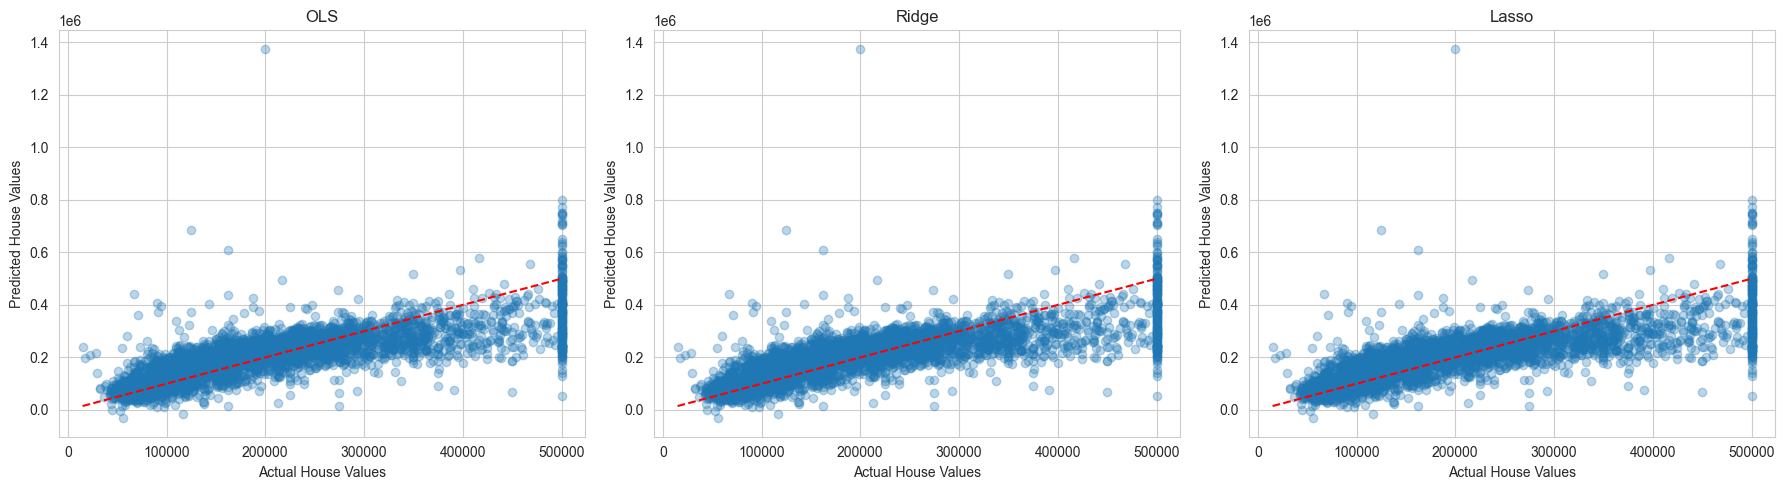

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, pred) in zip(axes, predictions.items()):

    ax.scatter(y_test, pred, alpha=0.3)

    ax.plot(
        [y_test.min(), y_test.max()],
        [y_test.min(), y_test.max()],
        'r--'
    )

    ax.set_title(name)
    ax.set_xlabel("Actual House Values")
    ax.set_ylabel("Predicted House Values")

plt.tight_layout()
plt.show()

## 36. Updated Residual Analysis

Residual distributions are plotted to examine prediction errors in the updated regression models.

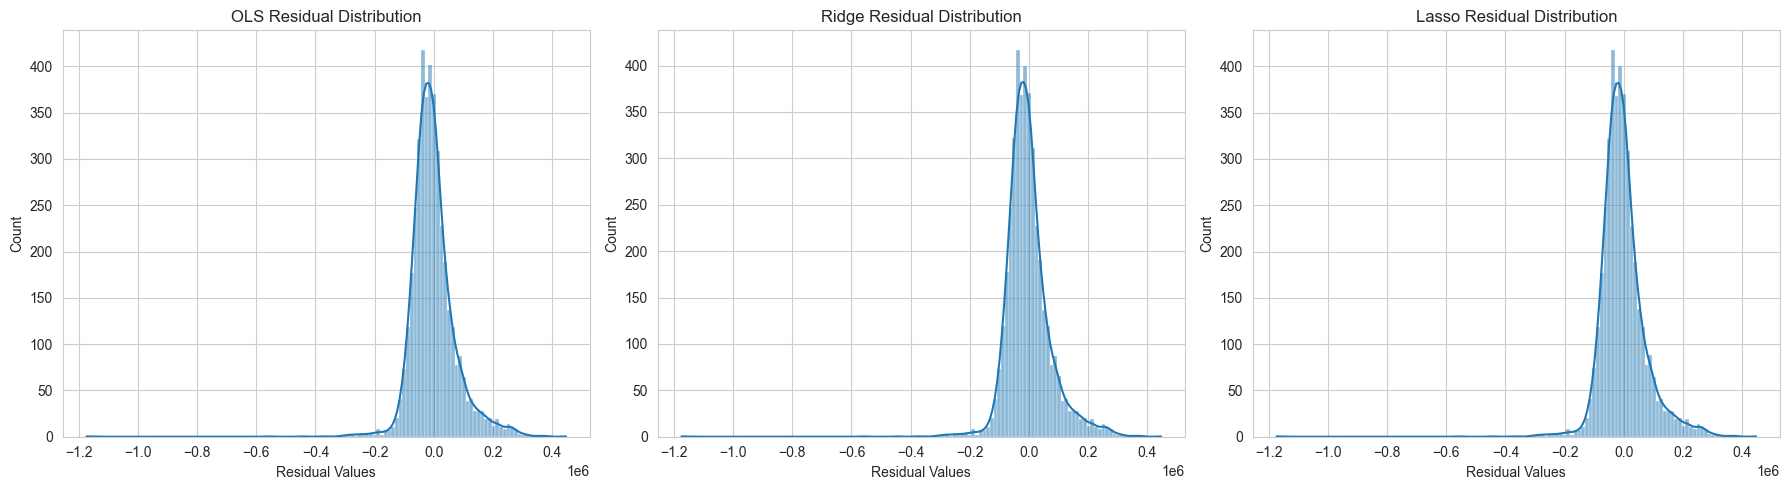

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, pred) in zip(axes, predictions.items()):

    residuals = y_test - pred

    sns.histplot(residuals, kde=True, ax=ax)

    ax.set_title(name + " Residual Distribution")
    ax.set_xlabel("Residual Values")

plt.tight_layout()
plt.show()

## 37. Conclusion

The California Housing Price Prediction project was implemented using OLS, Ridge, and Lasso regression algorithms.

Data preprocessing, feature engineering, interaction features, and multicollinearity analysis were performed.

GridSearchCV was used for hyperparameter tuning, and the models were evaluated using RMSE, MAE, and R² scores.

OLS achieved the lowest RMSE and MAE among the three models.

Actual versus predicted plots and residual distributions were generated to analyze model performance.

This project provided practical experience in regression modeling, regularization, feature engineering, and model evaluation using Python and Scikit-learn.

## 38. Final Model Performance

The final performance of OLS, Ridge, and Lasso regression models is displayed to identify the best-performing model.

In [ ]:
print("DATHEON INTERNSHIP - TASK 2")
print("FINAL MODEL PERFORMANCE")
print("-" * 50)

display(results_df.round(4))

best_model = results_df.loc[
    results_df['RMSE'].idxmin(), 'Model'
]

print("\nBest Performing Model:", best_model)
print("Dataset Used: California Housing Dataset")
print("Total Samples:", len(df))
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

DATHEON INTERNSHIP - TASK 2
FINAL MODEL PERFORMANCE
--------------------------------------------------


,Model,RMSE,MAE,R2 Score
0,OLS,76414.2677,52720.7071,0.5544
1,Ridge,76422.3339,52727.4811,0.5543
2,Lasso,76414.6372,52721.6498,0.5544



Best Performing Model: OLS
Dataset Used: California Housing Dataset
Total Samples: 20640
Training Samples: 16512
Testing Samples: 4128
